# Apartment Hunter – Estimer le prix d'une maison

**Projet « Chasseurs d'appart' »**

## 1. Introduction

### Contexte
Un agent immobilier doit souvent estimer le prix d'un bien pour un propriétaire qui veut vendre.
L'idée du projet est de l'aider avec un petit outil de machine learning : on rentre les caractéristiques d'une maison et l'outil propose un prix.

### Problématique
> **Peut-on estimer le prix d'une maison à partir de ses caractéristiques ?**

### Ce qu'on va faire
- Charger et comprendre les données
- Nettoyer les données
- Faire une analyse exploratoire avec des graphiques
- Choisir les variables les plus utiles
- Entraîner et comparer 3 modèles de régression
- Améliorer le meilleur avec un Grid Search
- Sauvegarder le modèle final pour l'utiliser dans une application Flask

### Pourquoi on fait ce choix
On avait le choix entre deux jeux de données : Madrid et King County.
On a pris **King County** (région de Seattle, États-Unis) parce qu'il a moins de colonnes, qu'il n'a pas de texte libre à traiter et que chaque variable est bien décrite.
C'est plus simple à nettoyer et à expliquer.

Le jeu de données contient des ventes de maisons entre mai 2014 et mai 2015. La variable à prédire est **`price`** (le prix de vente en dollars).

## 2. Import des librairies

### Ce qu'on va faire
On importe les librairies dont on aura besoin dans tout le notebook.

### Code

In [1]:
import os                           # créer le dossier des images
import pandas as pd                 # manipuler le tableau de données
import numpy as np                  # calculs (ex : racine carrée pour le RMSE)
import matplotlib.pyplot as plt     # graphiques
import joblib                       # sauvegarder le modèle
import sklearn

from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, GridSearchCV
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# On note la version de scikit-learn : il faudra la même dans requirements.txt pour l'application Flask
print("Version de scikit-learn :", sklearn.__version__)

Version de scikit-learn : 1.8.0


### Ce qu'on observe
Les imports fonctionnent et la version de scikit-learn s'affiche.

### Pourquoi on fait ce choix
On reste sur les librairies classiques vues en cours : **pandas** pour les données, **matplotlib** pour les graphiques, **scikit-learn** pour les modèles et **joblib** pour enregistrer le modèle.
La version de scikit-learn est importante : un modèle sauvegardé avec une version peut ne pas se recharger correctement avec une autre. On la recopiera dans `requirements.txt`.

## 3. Chargement et première inspection des données

### Ce qu'on va faire
On charge le fichier CSV puis on regarde rapidement à quoi ressemblent les données :
- `head()` : les premières lignes
- `shape` : le nombre de lignes et de colonnes
- `info()` : le type de chaque colonne et les valeurs non vides
- `describe()` : les statistiques de base (moyenne, min, max…)

> Sur Google Colab : créer un dossier `data` dans l'onglet *Fichiers* (à gauche) et y déposer `kc_house_data.csv`.

### Code

In [2]:
# Pour afficher toutes les colonnes du tableau
pd.set_option("display.max_columns", None)

df = pd.read_csv("data/kc_house_data.csv")
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [3]:
df.shape

(21613, 21)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [5]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


### Ce qu'on observe
- Le fichier contient **21 613 maisons** et **21 colonnes**, comme annoncé dans la description.
- Toutes les colonnes sont numériques sauf **`date`**, qui est du texte (ex : `20141013T000000`).
- `info()` indique 21 613 valeurs non nulles pour chaque colonne : a priori **aucune valeur manquante** (on le vérifiera dans le nettoyage).
- Le prix moyen est d'environ **540 000 $** mais le prix médian est de **450 000 $**. La moyenne est tirée vers le haut par quelques maisons très chères (maximum : **7,7 millions $**).
- Certaines valeurs paraissent bizarres :
  - une maison avec **33 chambres** (`bedrooms` max = 33)
  - des maisons avec **0 chambre** ou **0 salle de bain**

### Pourquoi on fait ce choix
Avant de faire quoi que ce soit, il faut savoir ce qu'il y a dans le fichier.
Ces 4 commandes suffisent pour repérer les problèmes à traiter ensuite : le type de `date`, et des valeurs anormales dans `bedrooms` et `bathrooms`.

## 4. Comprendre les variables

### Ce qu'on va faire
On s'appuie sur le fichier de description fourni pour comprendre chaque colonne, et on compte le nombre de valeurs différentes par colonne.

### Code

In [6]:
# Nombre de valeurs différentes dans chaque colonne
df.nunique()

id               21436
date               372
price             4028
bedrooms            13
bathrooms           30
sqft_living       1038
sqft_lot          9782
floors               6
waterfront           2
view                 5
condition            5
grade               12
sqft_above         946
sqft_basement      306
yr_built           116
yr_renovated        70
zipcode             70
lat               5034
long               752
sqft_living15      777
sqft_lot15        8689
dtype: int64

### Ce qu'on observe

| Variable | Signification | Remarque |
|---|---|---|
| `price` | Prix de vente ($) | **la cible** (ce qu'on veut prédire) |
| `bedrooms` | Nombre de chambres | |
| `bathrooms` | Nombre de salles de bain | 0,5 = toilettes sans douche |
| `sqft_living` | Surface habitable (pieds²) | 1 pied² ≈ 0,093 m² |
| `sqft_lot` | Surface du terrain | |
| `floors` | Nombre d'étages | |
| `waterfront` | Vue sur l'eau | 0 = non, 1 = oui |
| `view` | Qualité de la vue | note de 0 à 4 |
| `condition` | État de la maison | note de 1 à 5 |
| `grade` | Qualité de construction | note de 1 à 13 (7 = moyen) |
| `sqft_above` / `sqft_basement` | Surface hors sol / sous-sol | |
| `yr_built` | Année de construction | |
| `yr_renovated` | Année de rénovation | **0 = jamais rénovée** |
| `lat` / `long` | Latitude / longitude | la localisation |
| `sqft_living15` / `sqft_lot15` | Surfaces moyennes des 15 maisons voisines | |
| `id` | Identifiant de la vente | |
| `date` | Date de la vente | |
| `zipcode` | Code postal | 70 codes différents |

Avec `nunique()` on voit deux types de variables :
- des **notes** ou petites catégories avec peu de valeurs : `waterfront` (2), `view` (5), `condition` (5), `floors` (6), `grade` (12)
- des **vraies quantités** avec beaucoup de valeurs : surfaces, prix, `lat`, `long`…

On remarque aussi que `id` a 21 436 valeurs différentes pour 21 613 lignes : certains identifiants apparaissent plusieurs fois.

### Pourquoi on fait ce choix
Il faut comprendre les variables pour savoir lesquelles garder.
Par exemple, `grade`, `view` et `condition` sont déjà des notes rangées dans l'ordre (plus c'est haut, mieux c'est). On peut donc les laisser telles quelles, sans transformation.

## 5. Nettoyage des données

On vérifie, dans l'ordre :
1. les valeurs manquantes
2. les doublons
3. les types de données
4. les colonnes inutiles
5. les valeurs incohérentes
6. les valeurs extrêmes du prix

On garde une copie du nombre de lignes de départ pour voir à la fin combien on en a retiré.

In [7]:
nb_lignes_depart = df.shape[0]
nb_colonnes_depart = df.shape[1]

### 5.1 Valeurs manquantes

#### Ce qu'on va faire
On compte les cases vides dans chaque colonne.

#### Code

In [8]:
df.isna().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

#### Ce qu'on observe
**0 valeur manquante** dans toutes les colonnes.

#### Pourquoi on fait ce choix
Il n'y a rien à supprimer ni à remplacer (pas besoin d'imputation). On le vérifie quand même parce que c'est une étape demandée et que beaucoup de modèles plantent s'il y a des cases vides.

### 5.2 Doublons

#### Ce qu'on va faire
On cherche les lignes complètement identiques, puis les identifiants (`id`) qui reviennent plusieurs fois.

#### Code

In [9]:
print("Lignes en double :", df.duplicated().sum())
print("id qui apparaissent plusieurs fois :", df["id"].duplicated().sum())

Lignes en double : 0
id qui apparaissent plusieurs fois : 177


In [10]:
# Exemple : une maison dont l'id apparaît deux fois
id_en_double = df[df["id"].duplicated()]["id"].iloc[0]
df[df["id"] == id_en_double][["id", "date", "price", "bedrooms", "sqft_living"]]

,id,date,price,bedrooms,sqft_living
93,6021501535,20140725T000000,430000.0,3,1580
94,6021501535,20141223T000000,700000.0,3,1580


In [11]:
# Est-ce qu'il y a des lignes avec le même id ET la même date ?
df.duplicated(subset=["id", "date"]).sum()

np.int64(0)

#### Ce qu'on observe
- **0 ligne en double.**
- **177 identifiants** apparaissent deux fois, mais toujours avec une **date différente** (0 doublon sur `id` + `date`).
- Dans l'exemple, c'est la même maison vendue deux fois à quelques mois d'écart, avec deux prix différents.

#### Pourquoi on fait ce choix
On **garde** ces lignes : ce ne sont pas des erreurs mais deux vraies ventes. Une même maison peut être revendue quelques mois plus tard.

### 5.3 Types de données

#### Ce qu'on va faire
On regarde le type de chaque colonne.

#### Code

In [12]:
df.dtypes

id                 int64
date              object
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

#### Ce qu'on observe
Toutes les colonnes sont en `int64` ou `float64` (nombres), sauf **`date`** qui est en `object` (texte).

#### Pourquoi on fait ce choix
Les modèles de scikit-learn ont besoin de nombres. La seule colonne qui pose problème est `date`, et on va la supprimer juste après (voir 5.4), donc il n'y a aucune conversion à faire.

### 5.4 Colonnes inutiles

#### Ce qu'on va faire
On supprime les colonnes qui n'aident pas à prédire le prix ou qui répètent une information déjà présente :

| Colonne | Raison |
|---|---|
| `id` | C'est juste un numéro d'identification. Le numéro de la maison n'explique pas son prix. |
| `date` | Les ventes couvrent seulement environ 13 mois (mai 2014 → mai 2015). Pour garder le projet simple, on n'étudie pas l'effet du temps sur le prix (il faudrait transformer le texte de la date en mois ou en année). |
| `zipcode` | C'est un code, pas une quantité (98178 n'est pas « plus grand » que 98125). On a déjà `lat` et `long` pour la localisation. |
| `sqft_above` et `sqft_basement` | Leur somme donne exactement `sqft_living`. On garde seulement la surface totale. |

On vérifie d'abord la période couverte par `date` et la somme des surfaces avant de supprimer.

#### Code

In [13]:
# Période couverte par les ventes (le format AAAAMMJJ permet de trier le texte directement)
print("Première vente :", df["date"].min())
print("Dernière vente :", df["date"].max())

Première vente : 20140502T000000
Dernière vente : 20150527T000000


In [14]:
# Vérification : surface hors sol + sous-sol = surface habitable ?
(df["sqft_above"] + df["sqft_basement"] == df["sqft_living"]).all()

np.True_

In [15]:
df = df.drop(columns=["id", "date", "zipcode", "sqft_above", "sqft_basement"])
df.shape

(21613, 16)

#### Ce qu'on observe
- Les ventes vont du **2 mai 2014** au **27 mai 2015**, soit environ 13 mois.
- La vérification renvoie **True** : pour toutes les maisons, `sqft_above + sqft_basement = sqft_living`.
- Après suppression, il reste **16 colonnes** (le prix + 15 variables).

#### Pourquoi on fait ce choix
On enlève ce qui ne sert à rien ou qui est en double. Moins de colonnes = un modèle plus simple à comprendre et une application Flask avec moins de champs à remplir.
Pour `zipcode`, on évite aussi d'avoir à faire un encodage spécial des catégories : la latitude et la longitude sont déjà des nombres et représentent directement la position.

### 5.5 Valeurs incohérentes

#### Ce qu'on va faire
Dans `describe()`, on avait repéré une maison avec 33 chambres et des maisons avec 0 chambre ou 0 salle de bain. On les regarde de plus près.

#### Code

In [16]:
# Nombre de maisons pour chaque nombre de chambres
df["bedrooms"].value_counts().sort_index()

bedrooms
0       13
1      199
2     2760
3     9824
4     6882
5     1601
6      272
7       38
8       13
9        6
10       3
11       1
33       1
Name: count, dtype: int64

In [17]:
# Les maisons avec beaucoup de chambres
df[df["bedrooms"] >= 10][["price", "bedrooms", "bathrooms", "sqft_living"]]

,price,bedrooms,bathrooms,sqft_living
8757,520000.0,11,3.00,3000
13314,1148000.0,10,5.25,4590
15161,650000.0,10,2.00,3610
15870,640000.0,33,1.75,1620
19254,660000.0,10,3.00,2920


La maison avec 33 chambres ne fait que 1 620 pieds² (environ 150 m²) avec 1,75 salle de bain. C'est impossible : c'est très probablement une faute de frappe (33 au lieu de 3).
Les maisons avec 10 ou 11 chambres font entre 2 900 et 4 600 pieds², ce qui reste possible : on les garde.

In [18]:
df = df[df["bedrooms"] != 33]

In [19]:
# Les maisons sans chambre ou sans salle de bain
sans_chambre_ou_sdb = df[(df["bedrooms"] == 0) | (df["bathrooms"] == 0)]
print("Nombre de maisons concernées :", len(sans_chambre_ou_sdb))
sans_chambre_ou_sdb[["price", "bedrooms", "bathrooms", "sqft_living", "grade"]].sort_values("sqft_living")

Nombre de maisons concernées : 16


,price,bedrooms,bathrooms,sqft_living,grade
19452,142000.0,0,0.00,290,1
18379,265000.0,0,0.75,384,4
4868,228000.0,0,1.00,390,4
5832,280000.0,1,0.00,600,3
1149,75000.0,1,0.00,670,3
10481,484000.0,1,0.00,690,7
14423,139950.0,0,0.00,844,7
3467,288000.0,0,1.50,1430,7
9854,235000.0,0,0.00,1470,7
3119,380000.0,0,0.00,1470,8


On trouve des cas qui n'ont pas de sens pour une maison vendue : par exemple une maison de **4 810 pieds² à 1,3 million $ sans chambre ni salle de bain**, ou des maisons de 1 800 – 2 300 pieds² avec 2,5 salles de bain mais 0 chambre.
Ce sont sûrement des informations mal remplies. Elles ne représentent que 16 lignes sur plus de 21 000, on les supprime.

In [20]:
df = df[(df["bedrooms"] > 0) & (df["bathrooms"] > 0)]
df.shape

(21596, 16)

#### Ce qu'on observe
- **1 maison** supprimée pour les 33 chambres.
- **16 maisons** supprimées car elles avaient 0 chambre ou 0 salle de bain (dont 7 avec les deux à 0).
- Il reste **21 596 maisons**.

#### Pourquoi on fait ce choix
Ces lignes sont des erreurs de saisie évidentes. Si on les garde, le modèle apprend à partir de fausses informations.
On en supprime très peu (17 lignes, moins de 0,1 % des données) : on reste prudent et on ne perd presque rien.

### 5.6 Valeurs extrêmes du prix

#### Ce qu'on va faire
On regarde la distribution du prix avec une **boîte à moustaches** (boxplot), puis on compte les maisons au-dessus de la limite haute de la méthode **IQR** :

- Q1 = prix sous lequel se trouvent 25 % des maisons
- Q3 = prix sous lequel se trouvent 75 % des maisons
- IQR = Q3 − Q1
- limite haute = Q3 + 1,5 × IQR

#### Code

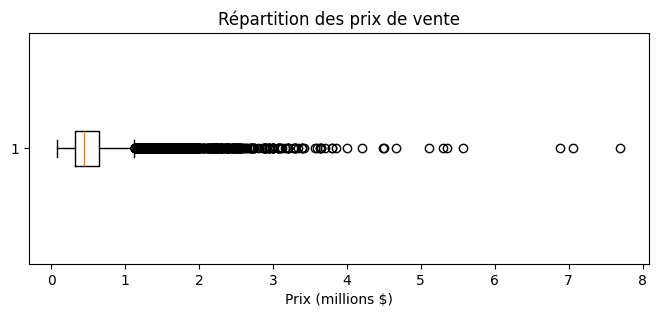

In [21]:
plt.figure(figsize=(8, 3))
# On divise par 1 000 000 pour lire l'axe en millions de dollars
plt.boxplot(df["price"] / 1000000, vert=False)
plt.title("Répartition des prix de vente")
plt.xlabel("Prix (millions $)")
plt.show()

In [22]:
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1
limite_haute = q3 + 1.5 * iqr

nb_maisons_cheres = (df["price"] > limite_haute).sum()
print("Q1 :", q1)
print("Q3 :", q3)
print("Limite haute :", limite_haute)
print("Maisons au-dessus de la limite :", nb_maisons_cheres)
print("Pourcentage :", round(nb_maisons_cheres / len(df) * 100, 1), "%")

Q1 : 322000.0
Q3 : 645000.0
Limite haute : 1129500.0
Maisons au-dessus de la limite : 1145
Pourcentage : 5.3 %


In [23]:
# Les 5 maisons les plus chères
df.sort_values("price", ascending=False).head(5)[["price", "bedrooms", "bathrooms", "sqft_living", "grade", "view", "waterfront"]]

,price,bedrooms,bathrooms,sqft_living,grade,view,waterfront
7252,7700000.0,6,8.00,12050,13,3,0
3914,7062500.0,5,4.50,10040,11,2,1
9254,6885000.0,6,7.75,9890,13,4,0
4411,5570000.0,5,5.75,9200,13,0,0
1448,5350000.0,5,5.00,8000,12,4,0


#### Ce qu'on observe
- Le boxplot montre beaucoup de points à droite : quelques maisons sont beaucoup plus chères que la majorité.
- La limite haute IQR est d'environ **1,13 million $**. **1 145 maisons** (5,3 %) sont au-dessus.
- Il n'y a aucune maison sous la limite basse.
- Les 5 maisons les plus chères (entre 5,3 et 7,7 millions $) sont très grandes (8 000 à 12 000 pieds²), avec une qualité de construction de 11 à 13 et souvent une belle vue. Leur prix est donc logique.

#### Pourquoi on fait ce choix
On **ne supprime pas** ces maisons. Une maison chère n'est pas une erreur : ce sont des maisons de luxe qui existent vraiment.
Si on les enlevait, on perdrait 5 % des données et le modèle ne saurait plus estimer les grandes maisons.
On a seulement supprimé les lignes **incohérentes** (5.5), pas les lignes **extrêmes**.

### 5.7 Normalisation / standardisation

#### Ce qu'on va faire
Rien, et voici pourquoi.

#### Pourquoi on fait ce choix
- Les arbres de décision et la forêt aléatoire découpent les données avec des seuils (« surface > 2 000 ? »). Changer l'échelle des variables ne change pas leurs résultats.
- Pour la régression linéaire, mettre à l'échelle ne change pas les prédictions : ça change seulement la valeur des coefficients.

Ne pas transformer les données garde aussi l'application Flask simple : l'utilisateur tape des valeurs normales (surface, nombre de chambres…) et on les donne directement au modèle.

### 5.8 Bilan du nettoyage

#### Code

In [24]:
print("Avant nettoyage :", nb_lignes_depart, "lignes et", nb_colonnes_depart, "colonnes")
print("Après nettoyage :", df.shape[0], "lignes et", df.shape[1], "colonnes")
print("Lignes supprimées :", nb_lignes_depart - df.shape[0])
print()
print("Colonnes restantes :")
print(list(df.columns))

Avant nettoyage : 21613 lignes et 21 colonnes
Après nettoyage : 21596 lignes et 16 colonnes
Lignes supprimées : 17

Colonnes restantes :
['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


#### Ce qu'on observe
- On passe de **21 613 lignes et 21 colonnes** à **21 596 lignes et 16 colonnes**.
- **17 lignes** supprimées (erreurs de saisie) et **5 colonnes** supprimées (`id`, `date`, `zipcode`, `sqft_above`, `sqft_basement`).

#### Pourquoi on fait ce choix
Le nettoyage est volontairement léger : les données étaient déjà de bonne qualité (pas de valeurs manquantes, pas de doublons).
On a seulement enlevé ce qui était faux ou inutile, et on a gardé les maisons chères qui sont réelles.

## 6. Analyse exploratoire des données

### Ce qu'on va faire
Le sujet demandait de faire l'analyse exploratoire avec Power BI. **On n'a pas Power BI**, donc on la refait directement en Python avec matplotlib.
On fait 7 graphiques, chacun pour répondre à une question simple sur le prix.
Chaque graphique est aussi enregistré en image dans le dossier `images/` : ces images sont regroupées dans le fichier `dashboard.html` du dépôt, qui remplace le tableau de bord Power BI.

Pour que les graphiques soient faciles à lire, les prix sont affichés **en millions de dollars**.

### Code

In [25]:
# Dossier où on enregistre les graphiques
os.makedirs("images", exist_ok=True)

# Prix en millions de dollars, plus lisible sur les graphiques
prix_millions = df["price"] / 1000000

### 6.1 Comment sont répartis les prix ?

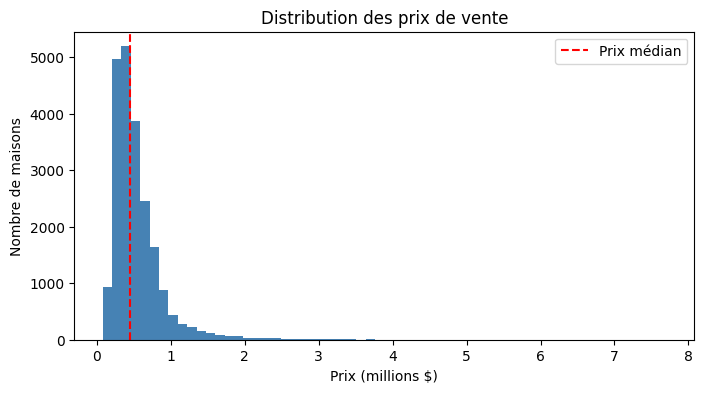

Prix médian : 450000.0
Part des maisons à moins de 1 million $ : 93.1 %


In [26]:
plt.figure(figsize=(8, 4))
plt.hist(prix_millions, bins=60, color="steelblue")
plt.axvline(prix_millions.median(), color="red", linestyle="--", label="Prix médian")
plt.title("Distribution des prix de vente")
plt.xlabel("Prix (millions $)")
plt.ylabel("Nombre de maisons")
plt.legend()
plt.savefig("images/1_distribution_prix.png", dpi=100, bbox_inches="tight")
plt.show()

print("Prix médian :", df["price"].median())
print("Part des maisons à moins de 1 million $ :", round((df["price"] < 1000000).mean() * 100, 1), "%")

#### Ce qu'on observe
- La grande majorité des maisons coûtent moins de 1 million $ (**93,1 %**). Le prix médian est de **450 000 $**.
- La distribution est très étirée vers la droite : il y a peu de maisons très chères, mais elles vont jusqu'à 7,7 millions $.

### 6.2 Est-ce que les maisons plus grandes sont plus chères ?

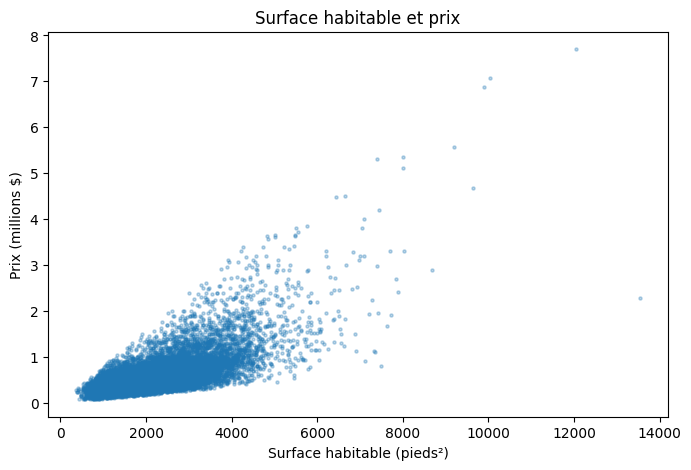

Corrélation surface / prix : 0.7


In [27]:
plt.figure(figsize=(8, 5))
plt.scatter(df["sqft_living"], prix_millions, s=5, alpha=0.3)
plt.title("Surface habitable et prix")
plt.xlabel("Surface habitable (pieds²)")
plt.ylabel("Prix (millions $)")
plt.savefig("images/2_surface_prix.png", dpi=100, bbox_inches="tight")
plt.show()

print("Corrélation surface / prix :", round(df["sqft_living"].corr(df["price"]), 2))

#### Ce qu'on observe
- On voit que le prix augmente globalement avec la surface habitable. La corrélation est de **0,70**, c'est le lien le plus fort avec le prix.
- Par contre, plus la maison est grande, plus les points sont dispersés : à surface égale, le prix peut beaucoup changer. D'autres choses jouent donc (qualité, emplacement…).

### 6.3 Est-ce que la qualité de construction (`grade`) joue sur le prix ?

On utilise le prix **médian** plutôt que la moyenne, parce que la médiane est moins influencée par les quelques maisons très chères.

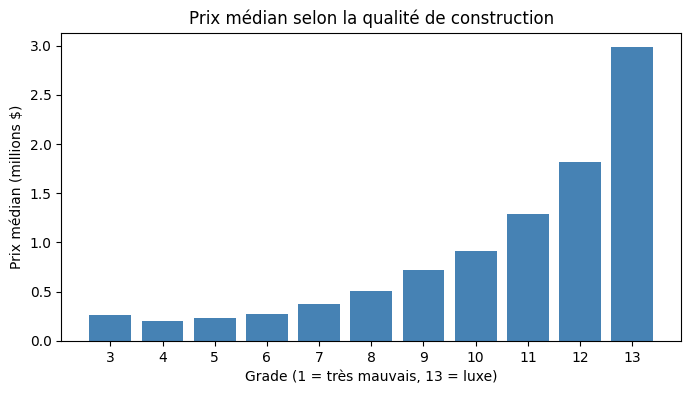

,prix médian (M$),nombre de maisons
grade,,
3,0.26,1
4,0.20,27
5,0.23,242
6,0.28,2038
7,0.38,8973
8,0.51,6065
9,0.72,2615
10,0.91,1134
11,1.28,399


In [28]:
prix_par_grade = df.groupby("grade")["price"].median() / 1000000

plt.figure(figsize=(8, 4))
plt.bar(prix_par_grade.index, prix_par_grade.values, color="steelblue")
plt.title("Prix médian selon la qualité de construction")
plt.xlabel("Grade (1 = très mauvais, 13 = luxe)")
plt.xticks(prix_par_grade.index)
plt.ylabel("Prix médian (millions $)")
plt.savefig("images/3_grade_prix.png", dpi=100, bbox_inches="tight")
plt.show()

# On affiche aussi le nombre de maisons dans chaque groupe
pd.DataFrame({"prix médian (M$)": prix_par_grade.round(2), "nombre de maisons": df["grade"].value_counts().sort_index()})

#### Ce qu'on observe
- Le prix médian augmente **globalement** avec la qualité de construction : **0,38 M$** pour le grade 7 (niveau moyen), **0,91 M$** pour le grade 10 et **2,98 M$** pour le grade 13.
- En bas de l'échelle, ce n'est pas parfaitement régulier : le grade 3 (0,26 M$) est au-dessus du grade 4 (0,20 M$). Mais il n'y a qu'**1 maison** au grade 3 et **27** au grade 4, donc ces médianes sont peu fiables. La hausse est nette et régulière à partir du grade 5.

### 6.4 Plus de chambres = plus cher ?

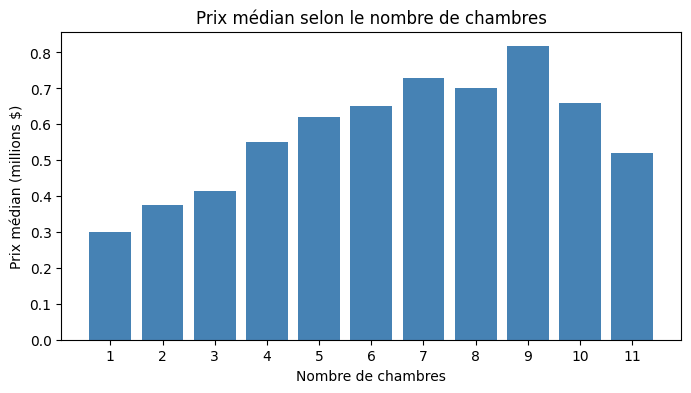

,prix médian (M$),nombre de maisons
bedrooms,,
1,0.30,196
2,0.37,2760
3,0.41,9824
4,0.55,6882
5,0.62,1601
6,0.65,272
7,0.73,38
8,0.70,13
9,0.82,6


In [29]:
prix_par_chambres = df.groupby("bedrooms")["price"].median() / 1000000

plt.figure(figsize=(8, 4))
plt.bar(prix_par_chambres.index, prix_par_chambres.values, color="steelblue")
plt.title("Prix médian selon le nombre de chambres")
plt.xlabel("Nombre de chambres")
plt.xticks(prix_par_chambres.index)
plt.ylabel("Prix médian (millions $)")
plt.savefig("images/4_chambres_prix.png", dpi=100, bbox_inches="tight")
plt.show()

# On affiche aussi le nombre de maisons dans chaque groupe
pd.DataFrame({"prix médian (M$)": prix_par_chambres.round(2), "nombre de maisons": df["bedrooms"].value_counts().sort_index()})

#### Ce qu'on observe
- La tendance monte globalement de 1 à environ 7 chambres (de **0,30 M$** pour 1 chambre à **0,73 M$** pour 7).
- Au-delà de 7 chambres, il y a très peu de maisons : 13 avec 8 chambres, 6 avec 9, 3 avec 10 et 1 avec 11. Les médianes montent et descendent, mais avec si peu de maisons **on ne peut pas en tirer une tendance fiable**.
- L'effet est moins fort que celui de la surface : une grande maison avec 3 chambres peut valoir plus qu'une petite maison avec 4 chambres.

### 6.5 Est-ce que la vue compte ?

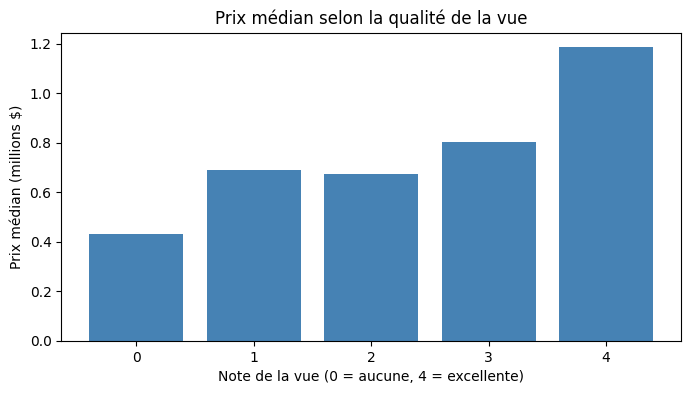

view
0    0.43
1    0.69
2    0.68
3    0.80
4    1.18
Name: price, dtype: float64

Prix médian sans vue sur l'eau : 450000.0
Prix médian avec vue sur l'eau : 1400000.0
Part des maisons avec vue sur l'eau : 0.75 %


In [30]:
prix_par_vue = df.groupby("view")["price"].median() / 1000000

plt.figure(figsize=(8, 4))
plt.bar(prix_par_vue.index, prix_par_vue.values, color="steelblue")
plt.title("Prix médian selon la qualité de la vue")
plt.xlabel("Note de la vue (0 = aucune, 4 = excellente)")
plt.ylabel("Prix médian (millions $)")
plt.savefig("images/5_vue_prix.png", dpi=100, bbox_inches="tight")
plt.show()

print(prix_par_vue.round(2))
print()
print("Prix médian sans vue sur l'eau :", df[df["waterfront"] == 0]["price"].median())
print("Prix médian avec vue sur l'eau :", df[df["waterfront"] == 1]["price"].median())
print("Part des maisons avec vue sur l'eau :", round(df["waterfront"].mean() * 100, 2), "%")

#### Ce qu'on observe
- Les maisons qui ont une vue sont plus chères : **0,43 M$** de prix médian sans vue, contre **1,18 M$** avec une vue excellente (note 4). Les notes 1 et 2 sont presque au même niveau (0,69 et 0,68 M$).
- La vue sur l'eau a un effet très fort : **1 400 000 $** de prix médian contre **450 000 $** sans, soit plus de 3 fois plus. Mais ça concerne très peu de maisons (moins de 1 %).

### 6.6 Est-ce que l'emplacement compte ?

On place chaque maison sur une carte avec sa latitude et sa longitude, et on la colore selon son prix.
Pour que les couleurs restent lisibles, toutes les maisons au-dessus de 2 millions $ ont la même couleur (rouge foncé).

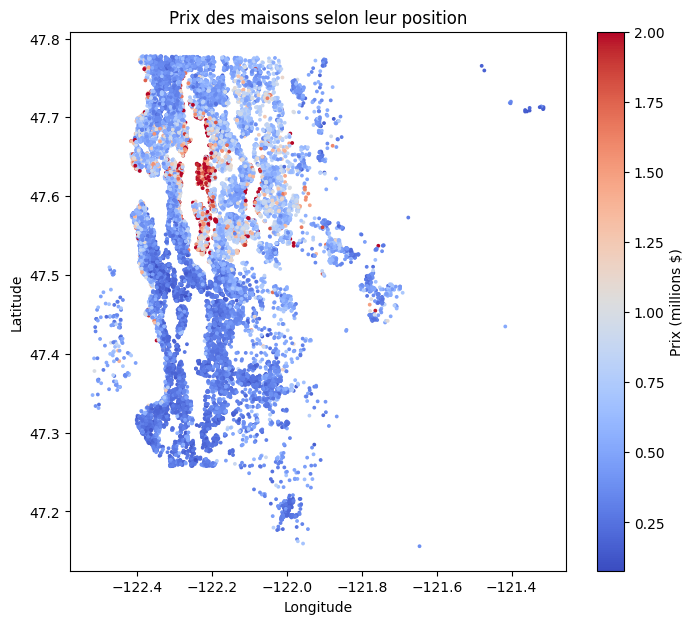

Corrélation latitude / prix : 0.31
Corrélation longitude / prix : 0.02


In [31]:
plt.figure(figsize=(8, 7))
plt.scatter(df["long"], df["lat"], c=prix_millions, cmap="coolwarm", vmax=2, s=3)
plt.colorbar(label="Prix (millions $)")
plt.title("Prix des maisons selon leur position")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.savefig("images/6_carte_prix.png", dpi=100, bbox_inches="tight")
plt.show()

print("Corrélation latitude / prix :", round(df["lat"].corr(df["price"]), 2))
print("Corrélation longitude / prix :", round(df["long"].corr(df["price"]), 2))

#### Ce qu'on observe
- On voit clairement des zones chères (en rouge), surtout au centre de la carte, autour de la latitude 47,6 et de la longitude -122,2. Le sud de la carte (latitude sous 47,5) est presque entièrement bleu, donc moins cher.
- Pourtant, la corrélation avec le prix n'est que de **0,31** pour la latitude et **0,02** pour la longitude.
- La localisation compte beaucoup, mais pas « en ligne droite » : ce n'est pas « plus on va vers l'est, plus c'est cher ». La corrélation ne voit pas ce genre de lien. C'est pour ça qu'on ne jette pas `lat` et `long` juste à cause de leur corrélation.

### 6.7 Quelles variables sont liées entre elles ?

La **corrélation** est un nombre entre -1 et 1 :
- proche de **1** : quand une variable augmente, l'autre augmente aussi
- proche de **0** : pas de lien en ligne droite
- proche de **-1** : quand l'une augmente, l'autre diminue

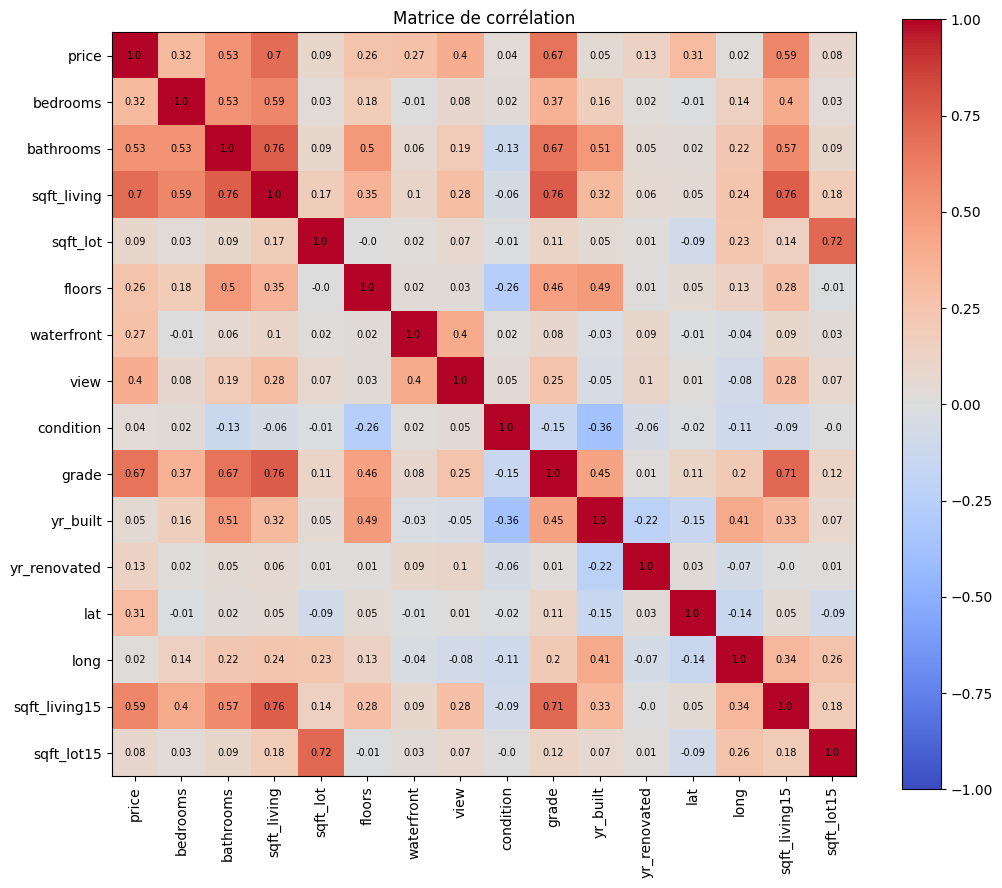

In [32]:
correlations = df.corr()

plt.figure(figsize=(12, 10))
plt.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(correlations.columns)), correlations.columns, rotation=90)
plt.yticks(range(len(correlations.columns)), correlations.columns)

# On écrit la valeur dans chaque case
for i in range(len(correlations.columns)):
    for j in range(len(correlations.columns)):
        plt.text(j, i, round(correlations.iloc[i, j], 2), ha="center", va="center", fontsize=7)

plt.title("Matrice de corrélation")
plt.savefig("images/7_correlations.png", dpi=100, bbox_inches="tight")
plt.show()

#### Ce qu'on observe
- La première ligne donne la corrélation avec le prix : `sqft_living` (0,70), `grade` (0,67), `sqft_living15` (0,59) et `bathrooms` (0,53) sont les plus liées.
- Certaines variables sont très liées entre elles : `sqft_living` avec `bathrooms`, `grade` et `sqft_living15` (0,76 à chaque fois), et `sqft_lot` avec `sqft_lot15` (0,72). Elles donnent donc en partie la même information.
- `condition`, `yr_built`, `long` et `sqft_lot` ont une corrélation proche de 0 avec le prix.

### Pourquoi on fait ces choix
On ne fait pas des dizaines de graphiques : chaque graphique répond à une question précise sur le prix.
Ça nous donne déjà une idée des variables importantes (surface, qualité, localisation) avant même d'utiliser une méthode de sélection.

## 7. Préparation des données pour les modèles

### Ce qu'on va faire
1. On sépare les **variables explicatives** (`X`, les caractéristiques de la maison) de la **cible** (`y`, le prix).
2. On découpe les données en deux :
   - **80 % pour l'entraînement** (train) : le modèle apprend sur ces maisons
   - **20 % pour le test** : on vérifie ensuite le modèle sur des maisons qu'il n'a **jamais vues**

### Code

In [33]:
# On sépare les variables explicatives du prix à prédire
X = df.drop(columns=["price"])
y = df["price"]

# 80 % entraînement / 20 % test. random_state=42 pour avoir toujours le même découpage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)

Entraînement : (17276, 15)
Test : (4320, 15)


### Ce qu'on observe
- **17 276 maisons** pour l'entraînement et **4 320 maisons** pour le test, avec 15 variables.

### Pourquoi on fait ce choix
Le train sert à apprendre, le test sert à évaluer le modèle sur des maisons qu'il n'a jamais vues. Si on évaluait le modèle sur les maisons qu'il a apprises, on aurait un score trop optimiste, un peu comme réviser avec les réponses de l'examen.
80/20 est un découpage classique, et avec plus de 21 000 maisons il reste assez de données des deux côtés.
Règle qu'on suit jusqu'à la fin : **tous les choix** (variables, modèle, paramètres) se font sur le train. Le test ne sert qu'**une seule fois**, à la fin, pour évaluer le modèle final.

## 8. Sélection des variables

On a encore 15 variables. On veut en garder moins pour deux raisons :
- un modèle plus simple à expliquer
- une application Flask avec un formulaire court

On utilise **deux méthodes** différentes, puis on choisit la liste finale.

**Important :** on fait la sélection **uniquement sur les données d'entraînement**. Le jeu de test doit rester « caché » jusqu'à l'évaluation finale, sinon on tricherait un peu.

### 8.1 Méthode 1 : corrélation avec le prix

#### Ce qu'on va faire
On calcule la corrélation de chaque variable avec le prix et on les classe.

#### Code

In [34]:
correlation_prix = X_train.corrwith(y_train).sort_values(ascending=False)
correlation_prix.round(3)

sqft_living      0.702
grade            0.669
sqft_living15    0.589
bathrooms        0.529
view             0.403
bedrooms         0.316
lat              0.305
waterfront       0.267
floors           0.257
yr_renovated     0.127
sqft_lot         0.085
sqft_lot15       0.080
yr_built         0.047
condition        0.043
long             0.017
dtype: float64

#### Ce qu'on observe
- On retrouve le même classement que dans la matrice : `sqft_living` (0,70), `grade` (0,67), `sqft_living15` (0,59), `bathrooms` (0,53) et `view` (0,40) sont en tête.
- `long` est dernière (0,017), alors que la carte a montré que l'emplacement compte.

#### Pourquoi on fait ce choix
C'est la méthode la plus simple pour avoir une première idée. Mais elle a deux limites :
- elle ne voit que les relations « en ligne droite » (d'où le cas de `long`)
- elle regarde chaque variable seule. Elle ne dit pas si deux variables donnent la même information (par exemple `sqft_living` et `bathrooms`, corrélées à 0,76).

C'est pour ça qu'on utilise une deuxième méthode.

### 8.2 Méthode 2 : sélection forward (pas à pas)

#### Ce qu'on va faire
On utilise `SequentialFeatureSelector` de scikit-learn en mode **forward** :
> On commence avec aucune variable, puis on ajoute à chaque étape la variable qui améliore le plus le modèle. On s'arrête quand on en a 8.

Pour tester chaque variable, il faut un modèle. On prend un **arbre de décision** (limité à 10 niveaux) parce que :
- il est rapide à entraîner (la méthode entraîne beaucoup de modèles)
- contrairement à la corrélation, il peut voir les relations qui ne sont pas en ligne droite, comme l'effet de la localisation

On demande **8 variables** : c'est un bon compromis entre précision et un formulaire pas trop long.

#### Code

In [35]:
arbre_selection = DecisionTreeRegressor(max_depth=10, random_state=42)

selection = SequentialFeatureSelector(arbre_selection, n_features_to_select=8, direction="forward", cv=3)
selection.fit(X_train, y_train)

variables_forward = list(X_train.columns[selection.get_support()])
print("Variables choisies par la sélection forward :")
print(variables_forward)

Variables choisies par la sélection forward :
['bedrooms', 'sqft_living', 'sqft_lot', 'waterfront', 'grade', 'yr_renovated', 'lat', 'long']


#### Ce qu'on observe
Les 8 variables retenues sont : `bedrooms`, `sqft_living`, `sqft_lot`, `waterfront`, `grade`, `yr_renovated`, `lat`, `long`.

- **`lat` et `long` sont gardées toutes les deux**, alors que `long` avait la plus faible corrélation. L'arbre arrive à utiliser la position, ce que la corrélation ne voyait pas.
- **`bathrooms`, `sqft_living15` et `view` ne sont pas gardées**, alors qu'elles avaient une bonne corrélation. Leur information est déjà en grande partie dans `sqft_living` et `grade` (corrélations de 0,71 à 0,76 entre elles), et pour `view` dans `waterfront` et la position.
- Les deux méthodes sont d'accord sur les deux variables les plus importantes : la surface et le grade.

#### Pourquoi on fait ce choix
La sélection forward regarde ce qu'une variable apporte **en plus** de celles déjà choisies. Elle évite donc de garder plusieurs variables qui disent la même chose.

### 8.3 Est-ce qu'on perd en précision avec seulement 8 variables ?

#### Ce qu'on va faire
On compare une forêt aléatoire entraînée avec **toutes les variables** et une entraînée avec les **8 variables choisies**.
Pour ne pas toucher au jeu de test, on utilise une **validation croisée** sur le train : on coupe le train en 3 parts, on entraîne sur 2 et on teste sur la 3ᵉ, trois fois, puis on fait la moyenne du R².

#### Code

In [36]:
foret = RandomForestRegressor(random_state=42, n_jobs=-1)

score_toutes = cross_val_score(foret, X_train, y_train, cv=3).mean()
score_selection = cross_val_score(foret, X_train[variables_forward], y_train, cv=3).mean()

print("R² avec les 15 variables :", round(score_toutes, 3))
print("R² avec les 8 variables  :", round(score_selection, 3))

R² avec les 15 variables : 0.856
R² avec les 8 variables  : 0.855


#### Ce qu'on observe
- R² de **0,856** avec les 15 variables et de **0,855** avec les 8 variables. C'est quasiment pareil.

#### Pourquoi on fait ce choix
Ce test montre qu'on peut enlever 7 variables sans perdre en précision. Le modèle est plus simple et le formulaire de l'application plus court.

### 8.4 Liste finale des variables

#### Code

In [37]:
variables_finales = variables_forward

# On ne garde que ces colonnes pour la suite
X_train = X_train[variables_finales]
X_test = X_test[variables_finales]

print(variables_finales)

['bedrooms', 'sqft_living', 'sqft_lot', 'waterfront', 'grade', 'yr_renovated', 'lat', 'long']


#### Ce qu'on observe

On garde les 8 variables de la sélection forward :

| Variable | Pourquoi elle est utile |
|---|---|
| `sqft_living` | La surface : le lien le plus fort avec le prix |
| `grade` | La qualité de construction : le prix augmente globalement avec le grade |
| `lat`, `long` | L'emplacement : on a vu des zones chères et moins chères sur la carte |
| `waterfront` | La vue sur l'eau : prix médian plus de 3 fois plus élevé |
| `sqft_lot` | La taille du terrain |
| `bedrooms` | Le nombre de chambres |
| `yr_renovated` | L'année de rénovation (0 si jamais rénovée) |

#### Pourquoi on fait ce choix
- On a la même précision qu'avec toutes les variables (partie 8.3).
- La liste est cohérente avec l'analyse exploratoire : surface, qualité et emplacement.
- 8 champs, ça reste un formulaire raisonnable pour l'application Flask.

## 9. Entraînement de trois modèles de régression

### Ce qu'on va faire
On fait de la **régression** : on veut prédire un nombre (le prix), pas une catégorie.
On teste 3 algorithmes classiques :

| Modèle | Idée en une phrase |
|---|---|
| **Régression linéaire** | Elle cherche la meilleure « formule » du type prix = a × surface + b × grade + … + constante. |
| **Arbre de décision** | Il pose des questions successives (« surface > 2 000 ? », « grade > 8 ? ») pour ranger les maisons en groupes de prix proches. |
| **Forêt aléatoire** (Random Forest) | Elle construit beaucoup d'arbres différents (100 par défaut) et fait la moyenne de leurs prédictions. |

Pour les comparer, on utilise 3 mesures :
- **MAE** (erreur absolue moyenne) : en moyenne, de combien de dollars le modèle se trompe.
- **RMSE** (racine de l'erreur quadratique moyenne) : aussi en dollars, mais les grosses erreurs comptent plus. Il est donc toujours plus grand que le MAE.
- **R²** : la part des variations du prix que le modèle arrive à expliquer. 1 = parfait, 0 = pas mieux que donner le prix moyen à tout le monde.

Pour MAE et RMSE, **plus c'est petit, mieux c'est**. Pour le R², **plus c'est proche de 1, mieux c'est**.

**Comment comparer sans toucher au jeu de test ?** On utilise la **validation croisée** sur le train, comme en 8.3 : le train est coupé en 3 parts, on entraîne sur 2 parts et on mesure l'erreur sur la 3ᵉ, trois fois, puis on fait la moyenne.
Le jeu de test reste de côté : il ne servira **qu'une seule fois**, à la fin, pour évaluer le modèle final. Si on choisissait le modèle en regardant le test, le score final serait un peu trop optimiste.

### Code

In [38]:
# Petite fonction qui calcule les 3 mesures par validation croisée (3 parts) sur le train
def evaluer_cv(nom, modele):
    scores = cross_validate(modele, X_train, y_train, cv=3,
                            scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
    # scikit-learn donne les erreurs en négatif, on remet le signe +
    # ("test_..." = la part mise de côté à chaque tour, pas notre jeu de test)
    mae = -scores["test_neg_mean_absolute_error"].mean()
    rmse = -scores["test_neg_root_mean_squared_error"].mean()
    r2 = scores["test_r2"].mean()
    return {"Modèle": nom, "MAE": round(mae), "RMSE": round(rmse), "R²": round(r2, 3)}

In [39]:
regression_lineaire = LinearRegression()
arbre = DecisionTreeRegressor(random_state=42)
foret = RandomForestRegressor(random_state=42, n_jobs=-1)

liste_resultats = [
    evaluer_cv("Régression linéaire", regression_lineaire),
    evaluer_cv("Arbre de décision", arbre),
    evaluer_cv("Forêt aléatoire (par défaut)", foret),
]
resultats = pd.DataFrame(liste_resultats)
resultats

,Modèle,MAE,RMSE,R²
0,Régression linéaire,138007,217074,0.652
1,Arbre de décision,102744,187545,0.740
2,Forêt aléatoire (par défaut),74266,139914,0.855


### Ce qu'on observe
Résultats en validation croisée sur le train :
- La **forêt aléatoire** est la meilleure sur les 3 mesures : MAE de **74 266 $**, RMSE de **139 914 $** et R² de **0,855**.
- L'**arbre de décision** est au milieu (R² de 0,740).
- La **régression linéaire** est la moins bonne (R² de 0,652) : elle se trompe en moyenne de **138 007 $**, presque deux fois plus que la forêt. C'est logique, puisque la carte a montré que le prix ne varie pas en ligne droite avec la latitude et la longitude. Une formule linéaire ne peut pas représenter ça.
- Pour les 3 modèles, le RMSE est bien plus grand que le MAE : il y a quelques grosses erreurs, probablement sur des maisons très chères ou atypiques.

### Pourquoi on fait ce choix
On compare les modèles **sans regarder le jeu de test** : tout se fait sur le train avec la validation croisée. Ici les 3 mesures donnent le même classement, donc le choix est clair : on garde la forêt aléatoire pour la suite.

### Est-ce que les modèles apprennent par cœur ? (surapprentissage)

On entraîne chaque modèle sur tout le train, puis on calcule son R² sur ces **mêmes maisons**, qu'il a déjà vues.
On compare avec le R² en validation croisée du tableau, qui est mesuré sur des maisons **qu'il n'a pas vues**.
Si le modèle est excellent sur les maisons apprises mais nettement moins bon sur les autres, il a appris « par cœur » au lieu de comprendre la tendance : c'est le **surapprentissage** (overfitting).

In [40]:
for nom, modele in [("Régression linéaire", regression_lineaire), ("Arbre de décision", arbre), ("Forêt aléatoire", foret)]:
    modele.fit(X_train, y_train)
    r2_train = r2_score(y_train, modele.predict(X_train))
    print(nom, "-> R² sur les maisons apprises :", round(r2_train, 3))

Régression linéaire -> R² sur les maisons apprises : 0.655
Arbre de décision -> R² sur les maisons apprises : 0.999


Forêt aléatoire -> R² sur les maisons apprises : 0.982


### Ce qu'on observe

| Modèle | R² sur les maisons apprises | R² en validation croisée |
|---|---|---|
| Régression linéaire | 0,655 | 0,652 |
| Arbre de décision | **0,999** | **0,740** |
| Forêt aléatoire | 0,982 | 0,855 |

- **Régression linéaire** : presque le même score des deux côtés. Pas de surapprentissage, mais le modèle est trop simple.
- **Arbre de décision** : presque parfait sur les maisons apprises, mais beaucoup moins bon sur les autres. Il a appris par cœur : sans limite de profondeur, il crée presque un groupe par maison.
- **Forêt aléatoire** : il y a aussi un écart, mais elle est bien meilleure que l'arbre seul sur les maisons qu'elle n'a pas vues. Faire la moyenne de 100 arbres un peu différents compense les erreurs de chaque arbre.

### Pourquoi on fait ce choix
Ce test explique pourquoi la forêt est meilleure que l'arbre seul. C'est tout l'intérêt de combiner plusieurs arbres.

## 10. Optimisation avec Grid Search

### Ce qu'on va faire
Jusqu'ici, la forêt aléatoire utilisait ses **paramètres par défaut**. On essaie de les améliorer avec `GridSearchCV` :
> Grid Search teste plusieurs combinaisons de paramètres et conserve celle qui donne les meilleurs résultats.

On le fait seulement sur la forêt aléatoire, le meilleur modèle de la partie 9.

On teste 3 paramètres :
- `n_estimators` : le nombre d'arbres dans la forêt
- `max_depth` : la profondeur maximale de chaque arbre (`None` = pas de limite)
- `min_samples_split` : le nombre minimum de maisons dans un groupe pour pouvoir encore le couper en deux

2 × 3 × 2 = **12 combinaisons**. Chaque combinaison est évaluée par validation croisée en 3 parts **sur le train**, donc 36 entraînements au total. Le jeu de test n'est pas utilisé. La grille est volontairement petite pour que ça tourne en quelques minutes sur Colab.

### Code

In [41]:
parametres = {
    "n_estimators": [100, 200],
    "max_depth": [10, 15, None],
    "min_samples_split": [2, 10],
}

grid = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), parametres, cv=3)
grid.fit(X_train, y_train)

print("Meilleurs paramètres :", grid.best_params_)
print("R² moyen en validation croisée :", round(grid.best_score_, 3))

Meilleurs paramètres : {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 200}
R² moyen en validation croisée : 0.856


On calcule ensuite les 3 mesures de la forêt optimisée, toujours en validation croisée sur le train, et on l'ajoute au tableau pour comparer les 4 modèles.

In [42]:
foret_optimisee = grid.best_estimator_

liste_resultats.append(evaluer_cv("Forêt aléatoire (Grid Search)", foret_optimisee))
resultats = pd.DataFrame(liste_resultats)
resultats

,Modèle,MAE,RMSE,R²
0,Régression linéaire,138007,217074,0.652
1,Arbre de décision,102744,187545,0.740
2,Forêt aléatoire (par défaut),74266,139914,0.855
3,Forêt aléatoire (Grid Search),73764,139413,0.856


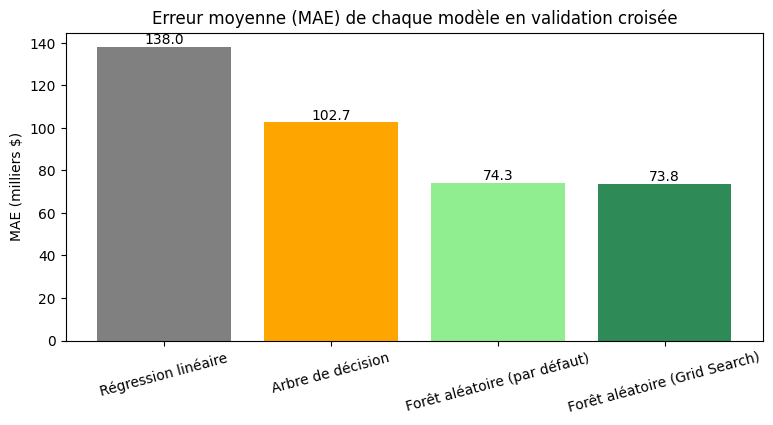

In [43]:
plt.figure(figsize=(9, 4))
barres = plt.bar(resultats["Modèle"], (resultats["MAE"] / 1000).round(1), color=["grey", "orange", "lightgreen", "seagreen"])
plt.bar_label(barres, fmt="%.1f")  # écrit la valeur au-dessus de chaque barre
plt.title("Erreur moyenne (MAE) de chaque modèle en validation croisée")
plt.ylabel("MAE (milliers $)")
plt.xticks(rotation=15)
plt.savefig("images/8_comparaison_modeles.png", dpi=100, bbox_inches="tight")
plt.show()

### Ce qu'on observe
- Meilleure combinaison : **200 arbres**, **profondeur maximale de 15** et `min_samples_split` = 2.
- En validation croisée sur le train :

| Forêt aléatoire | MAE | RMSE | R² |
|---|---|---|---|
| Paramètres par défaut | 74 266 $ | 139 914 $ | 0,855 |
| Après Grid Search | 73 764 $ | 139 413 $ | 0,856 |

- L'amélioration est **très petite** (environ 500 $ d'erreur moyenne en moins) : les paramètres par défaut étaient déjà bons.
- Sur le graphique, la forêt optimisée (vert foncé) a la plus petite erreur des 4, juste devant la forêt par défaut.

### Pourquoi on fait ce choix
Le but était surtout d'appliquer la méthode. Une grille plus grande prendrait beaucoup plus de temps pour un gain probablement très faible.
Tout est fait par validation croisée sur le train : le jeu de test n'a toujours pas été utilisé.

## 11. Modèle final

### Ce qu'on va faire
1. On choisit le modèle qui a le **meilleur R² en validation croisée** (donc sans regarder le test).
2. On l'évalue **une seule fois** sur le jeu de test.
3. On regarde quelles variables il utilise le plus et quelques exemples de prédictions.
4. On l'enregistre dans `model.pkl` pour l'application Flask.

### Code

In [44]:
# On retrouve chaque modèle à partir de son nom dans le tableau
modeles = {
    "Régression linéaire": regression_lineaire,
    "Arbre de décision": arbre,
    "Forêt aléatoire (par défaut)": foret,
    "Forêt aléatoire (Grid Search)": foret_optimisee,
}

meilleur = resultats.sort_values("R²", ascending=False).iloc[0]

# On l'entraîne sur tout le train
modele_final = modeles[meilleur["Modèle"]]
modele_final.fit(X_train, y_train)

print("Modèle final :", meilleur["Modèle"])

Modèle final : Forêt aléatoire (Grid Search)


### Évaluation finale sur le jeu de test

C'est la **seule fois** qu'on utilise les 4 320 maisons du test. Ce score montre comment le modèle se débrouille sur des maisons vraiment nouvelles.

In [45]:
predictions_test = modele_final.predict(X_test)

mae_test = mean_absolute_error(y_test, predictions_test)
rmse_test = np.sqrt(mean_squared_error(y_test, predictions_test))
r2_test = r2_score(y_test, predictions_test)

print("MAE  sur le test :", round(mae_test), "$")
print("RMSE sur le test :", round(rmse_test), "$")
print("R²   sur le test :", round(r2_test, 3))

MAE  sur le test : 71718 $
RMSE sur le test : 126924 $
R²   sur le test : 0.877


#### Ce qu'on observe
- Sur les 4 320 maisons du test : MAE de **71 718 $**, RMSE de **126 924 $** et R² de **0,877**.
- C'est proche de la validation croisée (R² de 0,856), et même un peu meilleur. Pendant la validation croisée, chaque modèle n'apprenait que sur 2/3 du train, alors que le modèle final apprend sur tout le train.

#### Pourquoi on fait ce choix
Le score sur le test confirme ce que disait la validation croisée : pas de mauvaise surprise sur des maisons nouvelles. Comme le test n'a servi à aucun choix, ce score est une estimation honnête de la précision du modèle.

### Quelles variables comptent le plus ?

Une forêt aléatoire peut indiquer l'**importance** de chaque variable : plus la valeur est haute, plus la variable a servi à faire baisser l'erreur. La somme fait 1.

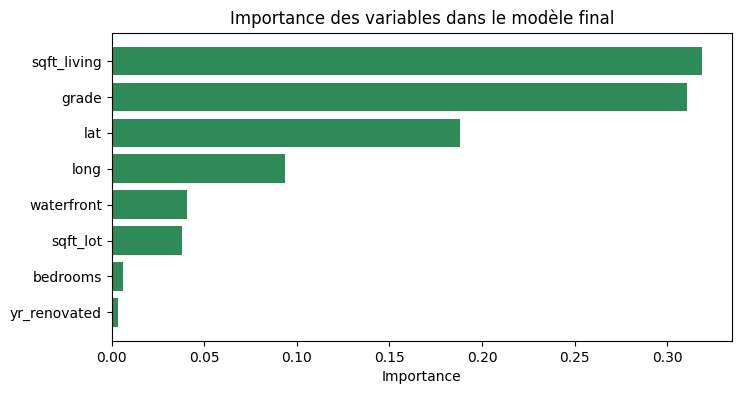

Nombre de maisons rénovées : 914 sur 21596


sqft_living     0.319
grade           0.311
lat             0.188
long            0.093
waterfront      0.041
sqft_lot        0.038
bedrooms        0.006
yr_renovated    0.003
dtype: float64

In [46]:
importances = pd.Series(modele_final.feature_importances_, index=variables_finales).sort_values()

plt.figure(figsize=(8, 4))
plt.barh(importances.index, importances.values, color="seagreen")
plt.title("Importance des variables dans le modèle final")
plt.xlabel("Importance")
plt.savefig("images/9_importance_variables.png", dpi=100, bbox_inches="tight")
plt.show()

print("Nombre de maisons rénovées :", (df["yr_renovated"] > 0).sum(), "sur", len(df))
importances.sort_values(ascending=False).round(3)

#### Ce qu'on observe
- `sqft_living` (0,319) et `grade` (0,311) représentent à eux deux presque **2/3** de l'importance.
- Ensuite vient l'emplacement : `lat` (0,188) + `long` (0,093), soit environ 0,28 à elles deux.
- `waterfront` (0,041) et `sqft_lot` (0,038) jouent un petit rôle.
- `bedrooms` (0,006) et `yr_renovated` (0,003) servent très peu. L'information sur les chambres est déjà en grande partie dans la surface, et seulement 914 maisons ont été rénovées.

#### Pourquoi on fait ce choix
Ça confirme ce qu'on avait vu dans l'analyse exploratoire : le prix dépend surtout de **la surface, la qualité et l'emplacement**.
On garde quand même `bedrooms` et `yr_renovated` : elles ont été choisies par la sélection, et le nombre de chambres est une information naturelle à demander dans un formulaire.

### Exemples sur 5 maisons du jeu de test

On reprend les prédictions déjà calculées pour l'évaluation finale.

In [47]:
# Les 5 premières maisons du test : prix réel et prix estimé
exemples = X_test.head(5).copy()
exemples["prix réel"] = y_test.head(5).values
exemples["prix estimé"] = predictions_test[:5].round()
exemples["écart (%)"] = ((exemples["prix estimé"] - exemples["prix réel"]) / exemples["prix réel"] * 100).round(1)
exemples

,bedrooms,sqft_living,sqft_lot,waterfront,grade,yr_renovated,lat,long,prix réel,prix estimé,écart (%)
3690,3,850,8573,0,6,0,47.5030,-122.356,132500.0,238995.0,80.4
10258,3,1510,6083,0,6,0,47.6966,-122.324,415000.0,375210.0,-9.6
4041,4,1790,42000,0,7,0,47.4819,-121.744,494000.0,422927.0,-14.4
3440,2,1140,2500,0,7,0,47.5707,-122.359,355000.0,313781.0,-11.6
19306,3,1500,3920,0,7,0,47.6718,-122.359,606000.0,575705.0,-5.0


#### Ce qu'on observe
- Pour 4 maisons sur 5, l'estimation est assez proche du vrai prix : entre **5 % et 14 %** d'écart.
- Pour la première maison, le modèle se trompe beaucoup : il estime **238 995 $** pour une maison vendue **132 500 $** (+80 %). Le modèle ne connaît que 8 caractéristiques : il ne peut pas savoir si cette maison était par exemple en très mauvais état ou vendue dans l'urgence.

#### Pourquoi on fait ce choix
Regarder quelques exemples concrets aide à comprendre ce que veut dire « une erreur moyenne de 72 000 $ » : souvent l'estimation est correcte, mais parfois le modèle se trompe beaucoup sur une maison particulière.

### Sauvegarde du modèle

On enregistre le modèle avec `joblib`. L'option `compress=3` réduit la taille du fichier : sans ça, une forêt aléatoire peut dépasser la limite de 100 Mo par fichier de GitHub.

> Sur Colab, il faudra ensuite télécharger `model.pkl` (clic droit dans l'onglet *Fichiers*) et le mettre dans le dépôt, à côté de `app.py`.

In [48]:
joblib.dump(modele_final, "model.pkl", compress=3)

print("Taille du fichier :", round(os.path.getsize("model.pkl") / 1000000, 1), "Mo")

Taille du fichier : 26.3 Mo


In [49]:
# On vérifie que le modèle se recharge bien, comme le fera l'application Flask
modele_recharge = joblib.load("model.pkl")
print("Prédiction avec le modèle rechargé :", round(modele_recharge.predict(X_test.head(1))[0]), "$")
print("Prédiction avec le modèle d'origine :", round(predictions_test[0]), "$")

Prédiction avec le modèle rechargé : 238995 $
Prédiction avec le modèle d'origine : 238995 $


#### Ce qu'on observe
- Le fichier `model.pkl` fait **26,3 Mo**, sous la limite de GitHub.
- Le modèle rechargé donne exactement la même prédiction que le modèle d'origine : l'application Flask donnera donc les mêmes résultats que le notebook.

#### Pourquoi on fait ce choix
`joblib` permet d'enregistrer le modèle entraîné dans un fichier. L'application n'a pas besoin de réentraîner le modèle à chaque lancement : elle charge `model.pkl` et fait directement des prédictions.
Comme on n'a fait aucune transformation des données (pas de normalisation, pas d'encodage), l'application a juste à donner les 8 valeurs tapées par l'utilisateur, dans le même ordre.

## 12. Conclusion

### Réponse à la problématique
> **Peut-on estimer le prix d'une maison à partir de ses caractéristiques ?**

**Oui, avec une précision correcte.** Le modèle final (forêt aléatoire optimisée par Grid Search) explique **87,7 %** des variations de prix sur des maisons qu'il n'a jamais vues (R² = 0,877). Il se trompe en moyenne de **71 718 $** (MAE), soit environ 16 % du prix médian (450 000 $).

### Ce qu'on retient
- Les données étaient propres : pas de valeurs manquantes ni de doublons. On a seulement retiré 17 lignes incohérentes et 5 colonnes inutiles.
- Le prix dépend surtout de **la surface**, de **la qualité de construction** et de **l'emplacement**.
- **8 variables** suffisent : on a la même précision qu'avec les 15.
- La **forêt aléatoire** est nettement meilleure que la régression linéaire et que l'arbre seul.
- Les choix (modèle, paramètres) ont été faits uniquement par validation croisée sur le train. Le jeu de test n'a servi qu'une fois, à la fin.
- Le **Grid Search** apporte une très petite amélioration.

### Limites
- C'est une **estimation**, pas un prix exact : l'erreur moyenne reste d'environ 72 000 $, et certaines erreurs sont beaucoup plus grandes (le RMSE est bien plus élevé que le MAE).
- Les données datent de **2014-2015** et ne concernent que le **comté de King** (région de Seattle). Le modèle ne peut pas servir tel quel pour une autre région ou pour les prix d'aujourd'hui.
- L'utilisateur doit connaître la latitude et la longitude de la maison.

### Pistes d'amélioration
- Utiliser des données plus récentes, et la date de vente si on a plusieurs années.
- Tester d'autres modèles plus avancés (par exemple le gradient boosting).
- Remplacer la saisie des coordonnées par une adresse dans l'application.